# 05 · Finding periods: GLS, PDC, USuRPER and partial periodograms

**What you'll learn**

- GLS and PDC periodograms of a scalar series (e.g. RVs), on a frequency grid in 1/day
- how the PDC is built: a distance matrix, its U-centring, and a cosine with the phase distances
- what a PDC p-value means, and why it is a *single-frequency* (local) p-value
- the error-aware PDC, for points with very different error bars
- USuRPER: a periodogram of the spectra themselves, with no RVs needed
- the partial periodograms, which separate Doppler shifts from line-shape changes

Every step is a call to a public function on plain arrays: `sparta.pdc` for the distance
correlation, astropy's `LombScargle` for GLS, `unicor` for the RVs. The last cell runs the same
analysis with the `PeriodicityDetector` object and checks that the numbers agree.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

from sparta.instruments.simulated import Simulation, component_spectra, simulate
from sparta.pdc import (error_aware_distance_matrix, inner_prod, partial_centering, pdc_power,
                        pdc_power_level, pdc_pvalue, phase_distance_matrix, scalar_distance_matrix,
                        spectral_distance_matrix, unbiased_u_centering)
from sparta.plotting import EXTRA_COLOR, GREY, apply_style, plot_curve
from sparta.preprocess import resample_to_log_grid
from unicor import ccf_order, doppler_shift_wave, dv_from_wave

apply_style()

def peak(freqs, power):
    """(period in days, power) of the highest peak of a periodogram on freqs (1/day)."""
    k = np.argmax(power)
    return 1 / freqs[k], power[k]

def power_at(freqs, power, period):
    """Power at the grid frequency closest to 1/period (period in days)."""
    return power[np.argmin(np.abs(freqs - 1 / period))]

## 1. A scalar series: GLS and PDC

40 measurements at random times over 100 days of a sinusoid with a 7.3-day period, plus noise:
two plain arrays, times in days and values.

In [2]:
rng = np.random.default_rng(42)
t = np.sort(rng.uniform(0, 100, 40))                   # days
P_true = 7.3
y = np.sin(2 * np.pi * t / P_true) + 0.5 * rng.standard_normal(t.size)
n = t.size

**The frequency grid.** Frequencies are in 1/day. A peak is about $1/T$ wide ($T$ = 100 days,
the time span), so the grid step must be several times finer than 0.01/day: 2000 points per
1/day, a step of 0.0005/day. The grid starts above 0 (the PDC's phase distance takes
$\Delta t \bmod 1/f$).

**GLS** (astropy's `LombScargle`, floating mean, standard normalisation) fits a sinusoid at
every trial frequency.

In [3]:
freqs = np.arange(0.01, 1.0, 1 / 2000)                 # 1/day, the end excluded
print(f"{freqs.size} frequencies from {freqs[0]} to {freqs[-1]:.4f} 1/day")

gls = LombScargle(t, y).power(freqs)
print(f"GLS: highest peak at P = {peak(freqs, gls)[0]:.3f} days (power {peak(freqs, gls)[1]:.3f})")

1980 frequencies from 0.01 to 0.9995 1/day
GLS: highest peak at P = 7.273 days (power 0.833)


**PDC** (Zucker 2018) asks a more general question: are pairs of points that are close in
*phase* also close in *value*? It is a distance correlation, so it works for any periodic shape.
Three steps:

1. the values' distances, $a_{ij} = |y_i - y_j|$ (`scalar_distance_matrix`);
2. U-centring, once (`unbiased_u_centering`; Székely & Rizzo 2014): row and column sums divided
   by $n-2$, the grand sum by $(n-1)(n-2)$, a zero diagonal. This gives the *unbiased* statistic,
   about 0 for unrelated data. Its factors are singular or negative for $n \le 3$, which raises;
3. at each trial frequency $f = 1/P$, the phase distances $b_{ij} = \varphi_{ij}(P - \varphi_{ij})$,
   $\varphi_{ij} = (t_i - t_j) \bmod P$ (`phase_distance_matrix`), U-centred the same way; the
   power is the cosine of the two centred matrices. `pdc_power` scans the grid.

In [4]:
a = scalar_distance_matrix(y)                          # (n, n), |y_i - y_j|
A = unbiased_u_centering(a, n)
pdc = pdc_power(t, freqs, A)                           # the unbiased PDC on the whole grid

# Step 3 by hand at the true period: the cosine under the U-centred inner product
B = unbiased_u_centering(phase_distance_matrix(t, 1 / P_true), n)
by_hand = inner_prod(A, B) / np.sqrt(inner_prod(A, A) * inner_prod(B, B))
scan = pdc_power(t, [1 / P_true], A)[0]
print(f"PDC at P = {P_true} d: by hand {by_hand:.6f}, pdc_power {scan:.6f}")
assert np.isclose(by_hand, scan, rtol=1e-12, atol=0)

print(f"PDC: highest peak at P = {peak(freqs, pdc)[0]:.3f} days (power {peak(freqs, pdc)[1]:.3f})")
try:
    unbiased_u_centering(a[:3, :3], 3)
except ValueError as err:
    print(f"three epochs: ValueError: {err}")

PDC at P = 7.3 d: by hand 0.640201, pdc_power 0.640201
PDC: highest peak at P = 7.326 days (power 0.643)
three epochs: ValueError: The unbiased (U-centered) PDC needs at least 4 epochs; got n = 3. Its 1/(n(n-3)) and /(n-2) factors are singular or negative for n <= 3.


**p-values.** `pdc_pvalue(power, n)` turns an unbiased PDC power into a p-value with the
$\chi^2_1$ approximation of Shen et al. (2019), $p = \chi^2_1.\mathrm{sf}(n \cdot \mathrm{power} + 1)$:
the probability of a peak this high *at one given frequency* if there were no signal, and
`pdc_power_level(p, n)` the power a p-value needs. It is local: searching many frequencies gives
noise many chances. A rough look-elsewhere factor is the number of independent frequencies,
about $T \times (f_{\max} - f_{\min})$.

In [5]:
p_local = pdc_pvalue(peak(freqs, pdc)[1], n)
n_indep = np.ptp(t) * (freqs[-1] - freqs[0])
level = pdc_power_level(1e-3, n)

print(f"local p-value of the PDC peak: {p_local:.1e}")
print(f"~{n_indep:.0f} independent frequencies -> global p-value roughly {min(1, p_local * n_indep):.1e}")
print(f"PDC power for a local p-value of 1e-3: {level:.3f}")
assert np.isclose(pdc_pvalue(level, n), 1e-3)

local p-value of the PDC peak: 2.4e-07
~92 independent frequencies -> global p-value roughly 2.2e-05
PDC power for a local p-value of 1e-3: 0.246


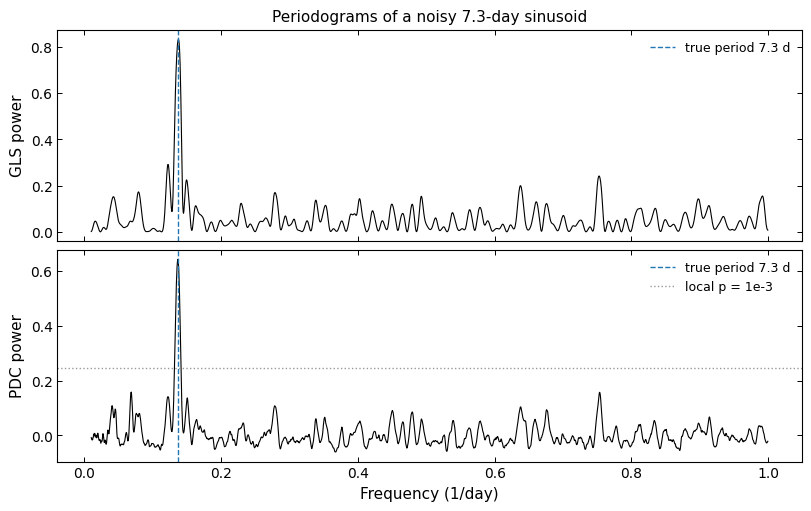

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, (name, power) in zip(axs, {"GLS": gls, "PDC": pdc}.items()):
    plot_curve(ax, freqs, power, lw=0.8)
    ax.axvline(1 / P_true, color=EXTRA_COLOR, ls="--", lw=1, label=f"true period {P_true} d")
    ax.set_ylabel(f"{name} power")
axs[1].axhline(level, color=GREY, ls=":", label="local p = 1e-3")
axs[0].set_title("Periodograms of a noisy 7.3-day sinusoid")
axs[1].set_xlabel("Frequency (1/day)")
axs[0].legend()
axs[1].legend()
plt.show()

## 2. When error bars differ: the error-aware PDC

If some points are much noisier than others, the plain PDC still treats them all alike. The
error-aware distance (Binnenfeld, Shahaf & Zucker 2024, Eq. 3, `error_aware_distance_matrix`)
uses each pair's error bars $e_i, e_j$:

$$d_{ij} = \sqrt{s\left(e^{-x^2} + x\,\mathrm{erf}(x) - \frac{e_i + e_j}{\sqrt2\,s}\right)},\qquad
s = \sqrt{e_i^2 + e_j^2},\quad x = \frac{y_i - y_j}{\sqrt2\,s}.$$

This is the published form, with no $\sqrt\pi$ on the $x\,\mathrm{erf}(x)$ term (the authors
confirmed it). With vanishing errors it tends to $(|y_i - y_j|/\sqrt2)^{1/2}$, a monotone
function of $|y_i - y_j|$ but not $|y_i - y_j|$ itself:

In [7]:
d_tiny = error_aware_distance_matrix([0.0, 1.0], [1e-6, 1e-6])[0, 1]
print(f"|Δy| = 1 with errors of 1e-6: d = {d_tiny:.6f}; (1/√2)^(1/2) = {2 ** -0.25:.6f}")
assert np.isclose(d_tiny, 2 ** -0.25, rtol=1e-5)

|Δy| = 1 with errors of 1e-6: d = 0.840896; (1/√2)^(1/2) = 0.840896


The rest of the PDC is unchanged: U-centre, then scan. One data set can go either way, so we
compare the two distances over 30 simulated data sets with exponentially distributed error bars,
and count how often the highest peak is the true period:

In [8]:
freqs_30 = np.arange(0.02, 1.0, 1 / 1000)              # 1/day
hits = {"plain": 0, "error-aware": 0}
for seed in range(30):
    r = np.random.default_rng(seed)
    ts = np.sort(r.uniform(0, 100, 40))
    err = r.exponential(1.0, ts.size)                  # very unequal error bars
    ys = np.sin(2 * np.pi * ts / P_true) + err * r.standard_normal(ts.size)
    distances = {"plain": scalar_distance_matrix(ys),
                 "error-aware": error_aware_distance_matrix(ys, err)}
    powers = {key: pdc_power(ts, freqs_30, unbiased_u_centering(d, ts.size))
              for key, d in distances.items()}
    for key, power in powers.items():
        hits[key] += abs(freqs_30[np.argmax(power)] - 1 / P_true) < 0.01

for key, n_hit in hits.items():
    print(f"{key:12s} PDC: true period found in {n_hit} of 30 data sets")

plain        PDC: true period found in 23 of 30 data sets
error-aware  PDC: true period found in 26 of 30 data sets


## 3. Periodograms of spectra: USuRPER

USuRPER (Binnenfeld, Shahaf & Zucker 2020) skips the RVs: it applies the PDC to the spectra
themselves, with the distance between two spectra as the "difference in value". Each spectrum is
resampled onto the wavelength range common to all, mean-subtracted and normalised, a point on a
unit sphere, and the distance is the chord between two points (`spectral_distance_matrix`;
notebook 07 builds it up). Any periodic change of the spectrum counts, whether a Doppler shift or
a change in the line shapes.

A toy star, simulated "like HARPS" (`simulate` returns one record of plain arrays per epoch): its
spectrum moves with a 7.3-day period ($K$ = 30 km/s), and a faint second spectrum (15% line
depth) moves *relative to it* with a 3.1-day period, so the combined line shapes change every
3.1 days. (Think of it as a stand-in for any line-profile variation.)

In [9]:
P1, P2 = 7.3, 3.1                                       # days
v1 = 30.0 * np.sin(2 * np.pi * t / P1)                  # km/s
v2 = v1 + 20.0 + 15.0 * np.sin(2 * np.pi * t / P2)

sim = Simulation(like="HARPS", windows_A=[(5000, 5100)], times=t, rv_kms=np.column_stack([v1, v2]),
                 components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0, amplitude=1.0),
                             dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.15)],
                 snr=100, noise="constant", seed=7)
records, truth = simulate(sim)
waves = [rec.wave[0] for rec in records]                # Å (air), one order per epoch
fluxes = [rec.flux[0] for rec in records]

d_spec = spectral_distance_matrix(waves, fluxes)        # chord distances on the unit sphere
usurper = pdc_power(t, freqs, unbiased_u_centering(d_spec, n))
print(f"USuRPER: highest peak at P = {peak(freqs, usurper)[0]:.3f} days")
print(f"USuRPER power at P1 = {P1} d: {power_at(freqs, usurper, P1):.3f}, "
      f"at P2 = {P2} d: {power_at(freqs, usurper, P2):.3f}")

USuRPER: highest peak at P = 7.299 days
USuRPER power at P1 = 7.3 d: 0.614, at P2 = 3.1 d: -0.042


USuRPER sees the dominant change, the 7.3-day Doppler shift; next to it, the much smaller
3.1-day shape change does not stand out.

## 4. Separating shifts from shapes: partial periodograms

The partial periodograms (Binnenfeld et al. 2022; notebook 08 builds them up) use the RVs to
split the two:

- **shift**: the periodicity of the RVs, with whatever the line-shape changes explain removed;
- **shape**: the periodicity of the spectra shifted to rest by the RVs (so only shape changes
  remain), with whatever the RVs explain removed.

First the RVs, against the primary's rest-frame model (`component_spectra`, the template the
simulator used). Each epoch is resampled onto a log-λ grid of step 0.1 km/s (notebook 01) and
cross-correlated with `unicor.ccf_order` (notebook 02); its native step, which sets the RV
uncertainty, is the step of the simulated pixels.

In [10]:
def measure_rvs(waves, fluxes, t_wave, t_flux, dv=0.1, vel_bound=60):
    """UNICOR RVs and their uncertainties (km/s) of single-order spectra against one template."""
    n_lags = int(round(vel_bound / dv))
    orders = []
    for w, f in zip(waves, fluxes):
        log_w, log_f = resample_to_log_grid(w, f, dv)
        orders.append(ccf_order(log_w, log_f, t_wave, t_flux, n_lags, dv_kms=dv,
                                native_step_kms=dv_from_wave(w), errors=True))
    return np.array([o.rv for o in orders]), np.array([o.erv for o in orders])

t_wave, t_flux = component_spectra(sim)[0][0]           # the primary, at rest, order 0
rv, erv = measure_rvs(waves, fluxes, t_wave, t_flux)
print(f"RV rms about the primary's true velocity: {np.std(rv - v1) * 1e3:.0f} m/s "
      "(the faint spectrum pulls the CCF)")

RV rms about the primary's true velocity: 73 m/s (the faint spectrum pulls the CCF)


The two distance matrices, and the partial statistic. `partial_centering(a, c)` U-centres the
searched matrix $a$ and the control $c$ and removes from $\tilde A$ its projection on $\tilde C$;
`pdc_power(..., control=C)` removes it from every U-centred phase matrix too, before the cosine.

In [11]:
rest_waves = [doppler_shift_wave(w, -v) for w, v in zip(waves, rv)]
shift_distance = scalar_distance_matrix(rv)                       # |v_i - v_j|
shape_distance = spectral_distance_matrix(rest_waves, fluxes)     # chord distance at rest

periodograms = {"GLS of the RVs": LombScargle(t, rv).power(freqs),
                "USuRPER (spectra)": usurper}
for name, (a_, c_) in {"partial: shift": (shift_distance, shape_distance),
                       "partial: shape": (shape_distance, shift_distance)}.items():
    A_, C_ = partial_centering(a_, c_)
    periodograms[name] = pdc_power(t, freqs, A_, control=C_)

for name, power in periodograms.items():
    print(f"{name:18s}: highest peak at P = {peak(freqs, power)[0]:.3f} days")
shape = periodograms["partial: shape"]
print(f"partial: shape power at P2 = {P2} d: {power_at(freqs, shape, P2):.3f}, "
      f"at P2/2 = {P2 / 2} d: {power_at(freqs, shape, P2 / 2):.3f}")

GLS of the RVs    : highest peak at P = 7.299 days
USuRPER (spectra) : highest peak at P = 7.299 days
partial: shift    : highest peak at P = 7.326 days
partial: shape    : highest peak at P = 3.101 days
partial: shape power at P2 = 3.1 d: 0.419, at P2/2 = 1.55 d: 0.380


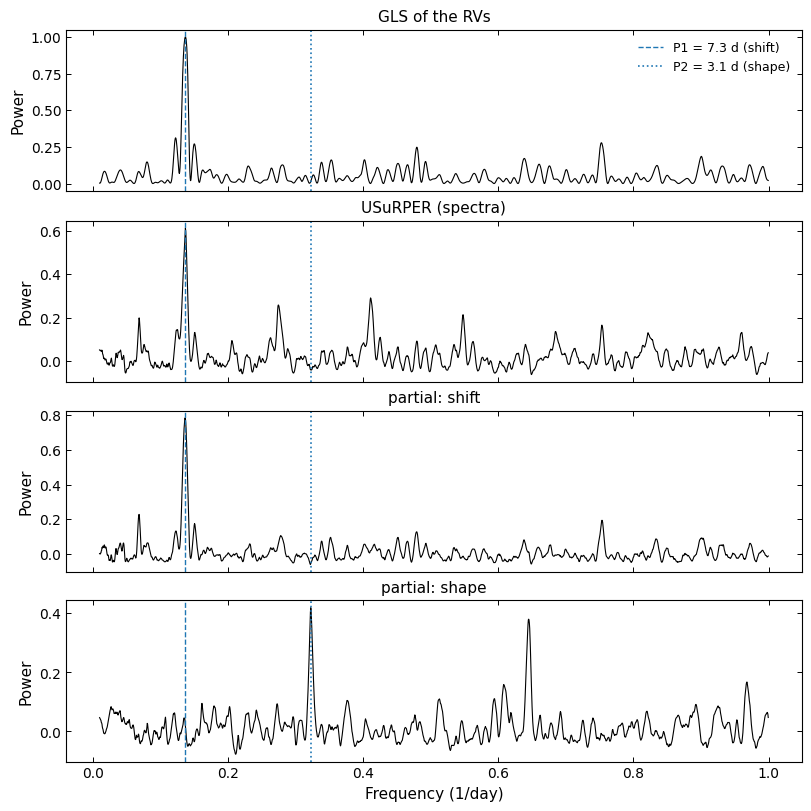

In [12]:
fig, axs = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
for ax, (name, power) in zip(axs, periodograms.items()):
    plot_curve(ax, freqs, power, lw=0.8)
    ax.axvline(1 / P1, color=EXTRA_COLOR, ls="--", lw=1, label=f"P1 = {P1} d (shift)")
    ax.axvline(1 / P2, color=EXTRA_COLOR, ls=":", lw=1.2, label=f"P2 = {P2} d (shape)")
    ax.set_ylabel("Power")
    ax.set_title(name)
axs[0].legend(loc="upper right")
axs[-1].set_xlabel("Frequency (1/day)")
plt.show()

Each periodogram answers a different question: the RVs and the shift periodogram see the orbit
(7.3 d), and only the shape periodogram picks out the 3.1-day line-shape change. Its second peak,
at half that period, is real too: the injected offset $20 + 15\sin\varphi$ km/s takes each value
twice per cycle, so the line shape does too.

## The same numbers with the objects

`Observations` and its `PeriodicityDetector` chain the same functions
([q04_periodograms](quickstart/q04_periodograms.ipynb) is the short recipe). The detector's grid,
GLS, PDC, p-values and USuRPER go through the same code, so they are identical, bit for bit.
`calc_rv_against_template` combines the orders by maximum likelihood (`combine_ccfs`,
notebook 02) on a lag axis computed once for all orders. With one order that is the same CCF up
to rounding, a different code path, so its RVs and the partial periodograms built on them are
compared to $10^{-9}$ (km/s for the RVs) rather than bit for bit.

In [13]:
from sparta import Observations, TimeSeries
from sparta.instruments.simulated import component_templates

obs = Observations(time_series=TimeSeries(times=t, vals=list(y)))
obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)
pd = obs.periodicity_detector
pd.calc_gls()
pd.calc_pdc()
assert np.array_equal(pd.frequency_grid, freqs)
assert np.array_equal(pd.results_power["GLS"], gls)
assert np.array_equal(pd.results_power["PDC_unbiased"], pdc)
assert np.array_equal(pd.calc_pdc_pval([1e-3], inverse_sf=True), pdc_power_level([1e-3], n))

last = Observations(time_series=TimeSeries(times=ts, vals=list(ys), errors=list(err)))
last.init_periodicity_detector(freq_range=(0.02, 1.0), periodogram_grid_resolution=1000)
last.periodicity_detector.calc_pdc(errors=True)                 # section 2, data set 29
assert np.array_equal(last.periodicity_detector.results_power["PDC_errors_unbiased"], powers["error-aware"])

spec_obs = Observations(survey="SIMULATED", simulation=sim)
spec_obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)
spd = spec_obs.periodicity_detector
spd.calc_usurper()
assert np.array_equal(spd.results_power["USURPER_unbiased"], usurper)

spec_obs.calc_rv_against_template(component_templates(sim)[0], dv=0.1, vel_bound=60)
spd.calc_partial_periodogram("shift")
spd.calc_partial_periodogram("shape")
assert np.allclose(spec_obs.vels, rv, rtol=0, atol=1e-9)        # km/s
assert np.allclose(spec_obs.evels, erv, rtol=0, atol=1e-9)
for key, name in (("partial_shift", "partial: shift"), ("partial_shape", "partial: shape")):
    assert np.allclose(spd.results_power[key], periodograms[name], rtol=0, atol=1e-9)
print("GLS, PDC, p-value levels, error-aware PDC, USuRPER: identical")
print(f"RVs: largest difference {np.max(np.abs(spec_obs.vels - rv)):.1e} km/s; partial periodograms: "
      f"{max(np.max(np.abs(spd.results_power[k] - periodograms[m])) for k, m in (('partial_shift', 'partial: shift'), ('partial_shape', 'partial: shape'))):.1e}")

GLS, PDC, p-value levels, error-aware PDC, USuRPER: identical
RVs: largest difference 0.0e+00 km/s; partial periodograms: 0.0e+00


## Summary / next

- The frequency grid is an array in 1/day, with a step several times finer than $1/T$; GLS is
  `LombScargle(t, y).power(freqs)`.
- The PDC is three atoms: a distance matrix (`scalar_distance_matrix`), `unbiased_u_centering`
  (raises for $n \le 3$), and `pdc_power` against the phase distances.
- `pdc_pvalue` / `pdc_power_level` are local, for one frequency; correct for the number of
  frequencies searched.
- `error_aware_distance_matrix` uses the error bars; with very unequal ones it found the true
  period more often.
- USuRPER is the same scan on `spectral_distance_matrix`; the partial periodograms
  (`partial_centering` and `pdc_power(..., control=...)`) tell Doppler shifts from line-shape
  changes.

**Next:** `06_end_to_end.ipynb`: from simulated spectra to a measured orbit.